# Étape 1.2 — Détection et traitement des valeurs aberrantes

> **Énoncé (1.2)** : identifier les valeurs aberrantes des variables quantitatives à l'aide de statistiques descriptives et de graphiques (boîtes à moustaches, histogrammes) ; les détecter par la méthode de l'écart interquartile (IQR) ou la règle des trois écarts-types ; proposer une stratégie de traitement (suppression, plafonnement, transformation ou conservation) et la justifier.

Ce notebook reprend le script `etape_1_2_aberrantes.py` : mêmes calculs, mêmes résultats, enregistrés dans `resultats/`. Les décisions et l'interprétation des résultats sont détaillées dans [README.md](README.md) (version LaTeX : `README.tex`).

**Contenu de l'étape :**


1. Statistiques descriptives et représentations graphiques (boîtes à moustaches, histogrammes).
2. Détection par la méthode de l'écart interquartile (IQR) et par la règle des trois écarts-types.
3. Stratégie de traitement par variable (conservation, plafonnement, transformation) et application.

Les valeurs impossibles ont déjà été mises à manquant à l'étape 1.1 ; on traite ici les valeurs
plausibles mais extrêmes.


## Préparation

Bibliothèques, module commun du projet, dossier de résultats et journal.

In [1]:
import sys
from pathlib import Path

# Le notebook s'exécute dans le dossier de l'étape : on remonte jusqu'à la racine du projet
RACINE_PROJET = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "commun" / "outils.py").exists())
sys.path.insert(0, str(RACINE_PROJET))

import numpy as np
import pandas as pd

from commun import outils as o

RES = o.dossier_resultats("1.2")
log = o.Journal(RES, "Étape 1.2 — Valeurs aberrantes")
plt = o.style_graphique()
C = o.COULEURS
BLEU, GRIS = o.SERIES[0], C["fond_point"]

df = o.lire_donnees("qualite")
log(f"Entrée : {o.DONNEES['qualite'].relative_to(o.RACINE)} — {df.shape[0]} individus")

EXPLICATIVES = ["age", "taille_menage", "nb_actifs_menage", "budget_alim", "budget_sante",
                "budget_elec", "anciennete_emploi", "distance_travail", "heures_jour", "jours_semaine"]
CIBLES = ["nb_maladies_graves", "cout_total"]
DESCRIPTIVES = ["prime_souhaitee", "jours_arret", "distance_soins"]
LIBELLES = {
    "age": "Âge (ans)", "taille_menage": "Taille du ménage", "nb_actifs_menage": "Actifs du ménage",
    "budget_alim": "% budget alimentation", "budget_sante": "% budget santé",
    "budget_elec": "% budget électricité", "anciennete_emploi": "Ancienneté (ans)",
    "distance_travail": "Distance au travail (km)", "heures_jour": "Heures / jour",
    "jours_semaine": "Jours / semaine", "nb_maladies_graves": "Maladies graves (12 mois)",
    "cout_total": "Coût du dernier épisode (Ar)", "prime_souhaitee": "Prime souhaitée (Ar)",
    "jours_arret": "Jours d'arrêt", "distance_soins": "Distance aux soins (km)",
}

# Étape 1.2 — Valeurs aberrantes


Entrée : partie1_donnees\1.1_qualite\resultats\donnees_qualite.csv — 4074 individus


## 1-2. Détection : IQR et 3 écarts-types

In [2]:
log.section("Détection : méthode IQR et règle des 3 écarts-types")


def detection(s: pd.Series) -> dict:
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    bi, bs = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m, e = s.mean(), s.std()
    return {"n": len(s), "moyenne": m, "ecart_type": e, "min": s.min(), "Q1": q1, "mediane": s.median(),
            "Q3": q3, "P99": s.quantile(0.99), "max": s.max(), "asymetrie": s.skew(),
            "borne_inf_iqr": bi, "borne_sup_iqr": bs, "hors_iqr": int(((s < bi) | (s > bs)).sum()),
            "borne_inf_3s": m - 3 * e, "borne_sup_3s": m + 3 * e,
            "hors_3s": int(((s < m - 3 * e) | (s > m + 3 * e)).sum())}


variables = EXPLICATIVES + CIBLES + DESCRIPTIVES
det = pd.DataFrame({v: detection(df[v]) for v in variables}).T
# Coût : la détection a plus de sens sur l'échelle logarithmique (coûts strictement positifs)
log_cout = np.log10(df.loc[df.cout_total > 0, "cout_total"])
det_log = detection(log_cout)
det.loc["log10(cout_total > 0)"] = det_log
det["pct_hors_iqr"] = 100 * det.hors_iqr / det.n
det["pct_hors_3s"] = 100 * det.hors_3s / det.n
o.sauver_table(det, RES, "detection_aberrantes", index=True)
log.table(det[["n", "Q1", "Q3", "borne_sup_iqr", "hors_iqr", "pct_hors_iqr", "moyenne", "ecart_type",
               "borne_sup_3s", "hors_3s", "pct_hors_3s", "P99", "max"]], floatfmt=",.2f")
log(f"log10(coût > 0) : bornes IQR [{10 ** det_log['borne_inf_iqr']:,.0f} ; "
    f"{10 ** det_log['borne_sup_iqr']:,.0f}] Ar, bornes 3σ [{10 ** det_log['borne_inf_3s']:,.0f} ; "
    f"{10 ** det_log['borne_sup_3s']:,.0f}] Ar");


## Détection : méthode IQR et règle des 3 écarts-types



,n,Q1,Q3,borne_sup_iqr,hors_iqr,pct_hors_iqr,moyenne,ecart_type,borne_sup_3s,hors_3s,pct_hors_3s,P99,max
age,"4,074.00",28.00,46.00,73.00,2.00,0.05,37.77,11.35,71.81,3.00,0.07,59.00,85.00
taille_menage,"4,074.00",3.00,5.00,8.00,96.00,2.36,4.48,1.88,10.11,27.00,0.66,10.00,30.00
nb_actifs_menage,"4,074.00",1.00,2.00,3.50,238.00,5.84,1.88,0.94,4.69,73.00,1.79,5.00,7.00
budget_alim,"4,074.00",48.00,70.00,103.00,190.00,4.66,54.02,21.19,117.59,0.00,0.00,100.00,100.00
budget_sante,"4,074.00",0.00,10.00,25.00,101.00,2.48,7.97,8.05,32.13,28.00,0.69,30.00,100.00
budget_elec,"4,074.00",1.00,10.00,23.50,42.00,1.03,6.48,6.06,24.66,40.00,0.98,24.00,100.00
anciennete_emploi,"4,074.00",5.00,19.00,40.00,8.00,0.20,11.93,9.20,39.53,21.00,0.52,37.00,50.00
distance_travail,"4,074.00",0.30,2.00,4.55,329.00,8.08,1.93,12.32,38.89,5.00,0.12,10.00,510.00
heures_jour,"4,074.00",6.00,8.00,11.00,357.00,8.76,7.61,3.16,17.10,71.00,1.74,24.00,24.00
jours_semaine,"4,074.00",6.00,6.00,6.00,"1,736.00",42.61,5.82,0.92,8.59,116.00,2.85,7.00,7.00


log10(coût > 0) : bornes IQR [377 ; 371,057] Ar, bornes 3σ [177 ; 815,282] Ar


## 3. Stratégie de traitement

In [3]:
log.section("Stratégie de traitement par variable")
p99 = {v: df[v].quantile(0.99) for v in variables}
positifs = df.loc[df.cout_total > 0, "cout_total"]
SEUIL_COUT = float(positifs.quantile(0.99))
STRATEGIE = {
    # variable : (traitement, seuil haut appliqué ou None, justification)
    "age": ("Conservation", None,
            "Après l'étape 1.1, l'âge va de 18 à 85 ans : les 3 valeurs hors IQR (80-85 ans) sont "
            "réelles et peu nombreuses."),
    "taille_menage": ("Plafonnement au P99", p99["taille_menage"],
                      "Les grands ménages existent mais 20 ou 30 personnes relèvent d'un foyer "
                      "collectif ; le plafond limite leur poids dans les distances du K-means."),
    "nb_actifs_menage": ("Conservation", None,
                         "Valeurs de 0 à 7, toutes plausibles et cohérentes avec la taille du ménage."),
    "budget_alim": ("Conservation", None,
                    "Variable bornée à [0 ; 100] % après l'étape 1.1 : pas d'extrême possible."),
    "budget_sante": ("Plafonnement au P99", p99["budget_sante"],
                     "Distribution très asymétrique : quelques parts de 50 à 80 % pèsent fortement "
                     "dans les distances standardisées."),
    "budget_elec": ("Plafonnement au P99", p99["budget_elec"],
                    "Même raison que pour le budget santé."),
    "anciennete_emploi": ("Conservation", None,
                          "Plafonnée logiquement par l'âge à l'étape 1.1 (≤ âge − 5) ; maximum de 50 ans "
                          "pour des actifs de plus de 55 ans."),
    "distance_travail": ("Plafonnement au P99", p99["distance_travail"],
                         "Queue extrême (300 et 510 km) issue de saisies ambiguës (« 200a 1000km ») ou "
                         "de déplacements exceptionnels."),
    "heures_jour": ("Plafonnement à 16 h", 16.0,
                    "Les réponses « 24 h » ou « 24/24 » décrivent un temps de présence (gardiennage, "
                    "commerce à domicile), pas un travail effectif ; 16 h est proche de la borne "
                    "des 3 écarts-types."),
    "jours_semaine": ("Conservation", None,
                      "Variable bornée à [1 ; 7] ; l'IQR est nul (Q1 = Q3 = 6) et signale à tort "
                      "toute valeur différente de 6."),
    "nb_maladies_graves": ("Plafonnement au P99", p99["nb_maladies_graves"],
                           "Au-delà de 10 maladies graves par an (jusqu'à 365), la réponse compte des "
                           "jours ou des crises d'une même maladie chronique, pas des sinistres "
                           "distincts. L'IQR (≥ 4) couperait 9 % de comptages normaux et la règle 3σ "
                           "est faussée par ces valeurs elles-mêmes (seuil à 43, effet de masque)."),
    "cout_total": ("Écrêtement au P99 des coûts positifs", SEUIL_COUT,
                   "Les sinistres graves (hospitalisation, chimiothérapie : jusqu'à 9,5 M Ar) sont "
                   "réels : on ne les supprime pas, mais on les plafonne pour le GLM de sévérité ; "
                   "l'excédent est réparti sur toutes les primes à l'étape 3.3 (méthode actuarielle "
                   "classique d'écrêtement). Le coût brut est conservé (cout_total_brut)."),
    "prime_souhaitee": ("Plafonnement au P99", p99["prime_souhaitee"],
                        "Variable d'opinion utilisée en discussion : le plafond évite qu'une réponse "
                        "isolée (200 000 Ar) fausse les moyennes."),
    "jours_arret": ("Plafonnement au P99", p99["jours_arret"],
                    "Variable descriptive : les arrêts de plusieurs mois sont réels mais rares."),
    "distance_soins": ("Plafonnement au P99", p99["distance_soins"],
                       "Variable descriptive : soins à Antananarivo ou Antsirabe (90 km et plus)."),
}

traite = df.copy()
for v in ["nb_maladies_graves", "cout_total"]:
    traite[f"{v}_brut"] = df[v]
lignes = []
for v, (traitement, seuil, justification) in STRATEGIE.items():
    modifiees = 0
    if seuil is not None:
        masque = traite[v] > seuil
        modifiees = int(masque.sum())
        traite.loc[masque, v] = seuil
    lignes.append({"variable": v, "role": "explicative" if v in EXPLICATIVES else
                   ("cible" if v in CIBLES else "descriptive"),
                   "hors_iqr": int(det.loc[v, "hors_iqr"]), "hors_3s": int(det.loc[v, "hors_3s"]),
                   "traitement": traitement, "seuil": seuil, "valeurs_modifiees": modifiees,
                   "pct_modifiees": 100 * modifiees / df[v].notna().sum(),
                   "justification": justification})
strategie = pd.DataFrame(lignes)
o.sauver_table(strategie, RES, "traitement_aberrantes")
log.table(strategie.drop(columns="justification"), index=False, floatfmt=",.2f");


## Stratégie de traitement par variable



variable,role,hors_iqr,hors_3s,traitement,seuil,valeurs_modifiees,pct_modifiees
age,explicative,2,3,Conservation,,0,0.00
taille_menage,explicative,96,27,Plafonnement au P99,10.00,27,0.66
nb_actifs_menage,explicative,238,73,Conservation,,0,0.00
budget_alim,explicative,190,0,Conservation,,0,0.00
budget_sante,explicative,101,28,Plafonnement au P99,30.00,28,0.69
budget_elec,explicative,42,40,Plafonnement au P99,24.00,40,0.98
anciennete_emploi,explicative,8,21,Conservation,,0,0.00
distance_travail,explicative,329,5,Plafonnement au P99,10.00,34,0.83
heures_jour,explicative,357,71,Plafonnement à 16 h,16.00,71,1.74
jours_semaine,explicative,1736,116,Conservation,,0,0.00


In [4]:
# Effet du traitement sur les deux cibles
log.section("Effet sur les variables cibles")
avant_n, apres_n = df.nb_maladies_graves.dropna(), traite.nb_maladies_graves.dropna()
effet_n = pd.DataFrame({
    "avant": [avant_n.mean(), avant_n.var(), avant_n.var() / avant_n.mean(), avant_n.max()],
    "apres": [apres_n.mean(), apres_n.var(), apres_n.var() / apres_n.mean(), apres_n.max()],
}, index=["moyenne", "variance", "variance / moyenne", "maximum"])
o.sauver_table(effet_n, RES, "effet_frequence", index=True)
log("Nombre de maladies graves :")
log.table(effet_n, floatfmt=",.3f")
cp_av, cp_ap = df.loc[df.cout_total > 0, "cout_total"], traite.loc[traite.cout_total > 0, "cout_total"]
effet_c = pd.DataFrame({
    "avant": [len(cp_av), cp_av.mean(), cp_av.median(), cp_av.std() / cp_av.mean(), cp_av.max(), cp_av.sum()],
    "apres": [len(cp_ap), cp_ap.mean(), cp_ap.median(), cp_ap.std() / cp_ap.mean(), cp_ap.max(), cp_ap.sum()],
}, index=["coûts positifs", "moyenne", "médiane", "coefficient de variation", "maximum", "somme"])
effet_c.loc["part de la charge écrêtée (%)"] = [np.nan, 100 * (1 - cp_ap.sum() / cp_av.sum())]
o.sauver_table(effet_c, RES, "effet_cout", index=True)
log(f"Coût total (individus avec coût > 0), seuil d'écrêtement = {SEUIL_COUT:,.0f} Ar :")
log.table(effet_c, floatfmt=",.2f")

o.ecrire_donnees(traite, o.DONNEES["aberrantes"], excel=True)
log(f"Jeu traité : {traite.shape[0]} × {traite.shape[1]} -> {o.DONNEES['aberrantes'].relative_to(o.RACINE)}");


## Effet sur les variables cibles

Nombre de maladies graves :


,avant,apres
moyenne,2.250,1.605
variance,190.102,2.532
variance / moyenne,84.476,1.577
maximum,365.000,10.000


Coût total (individus avec coût > 0), seuil d'écrêtement = 530,000 Ar :


,avant,apres
coûts positifs,"3,054.00","3,054.00"
moyenne,"41,191.15","32,683.29"
médiane,"13,004.50","13,004.50"
coefficient de variation,5.29,2.28
maximum,"9,500,000.00","530,000.00"
somme,"125,797,773.00","99,814,773.00"
part de la charge écrêtée (%),,20.65


Jeu traité : 4074 × 61 -> partie1_donnees\1.2_aberrantes\resultats\donnees_sans_aberrantes.csv


## Figures

In [5]:
def boites(ax, serie, titre):
    s = serie.dropna()
    ax.boxplot(s, vert=False, widths=0.5, patch_artist=True, showfliers=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLEU, lw=1.2),
               medianprops=dict(color=BLEU, lw=2), whiskerprops=dict(color=BLEU, lw=1.2),
               capprops=dict(color=BLEU, lw=1.2),
               flierprops=dict(marker="o", markersize=3.5, markerfacecolor=o.SERIES[1],
                               markeredgecolor=C["surface"], markeredgewidth=0.6, alpha=0.8))
    ax.set_title(titre, fontsize=9.5)
    ax.set_yticks([])
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(o.format_milliers)

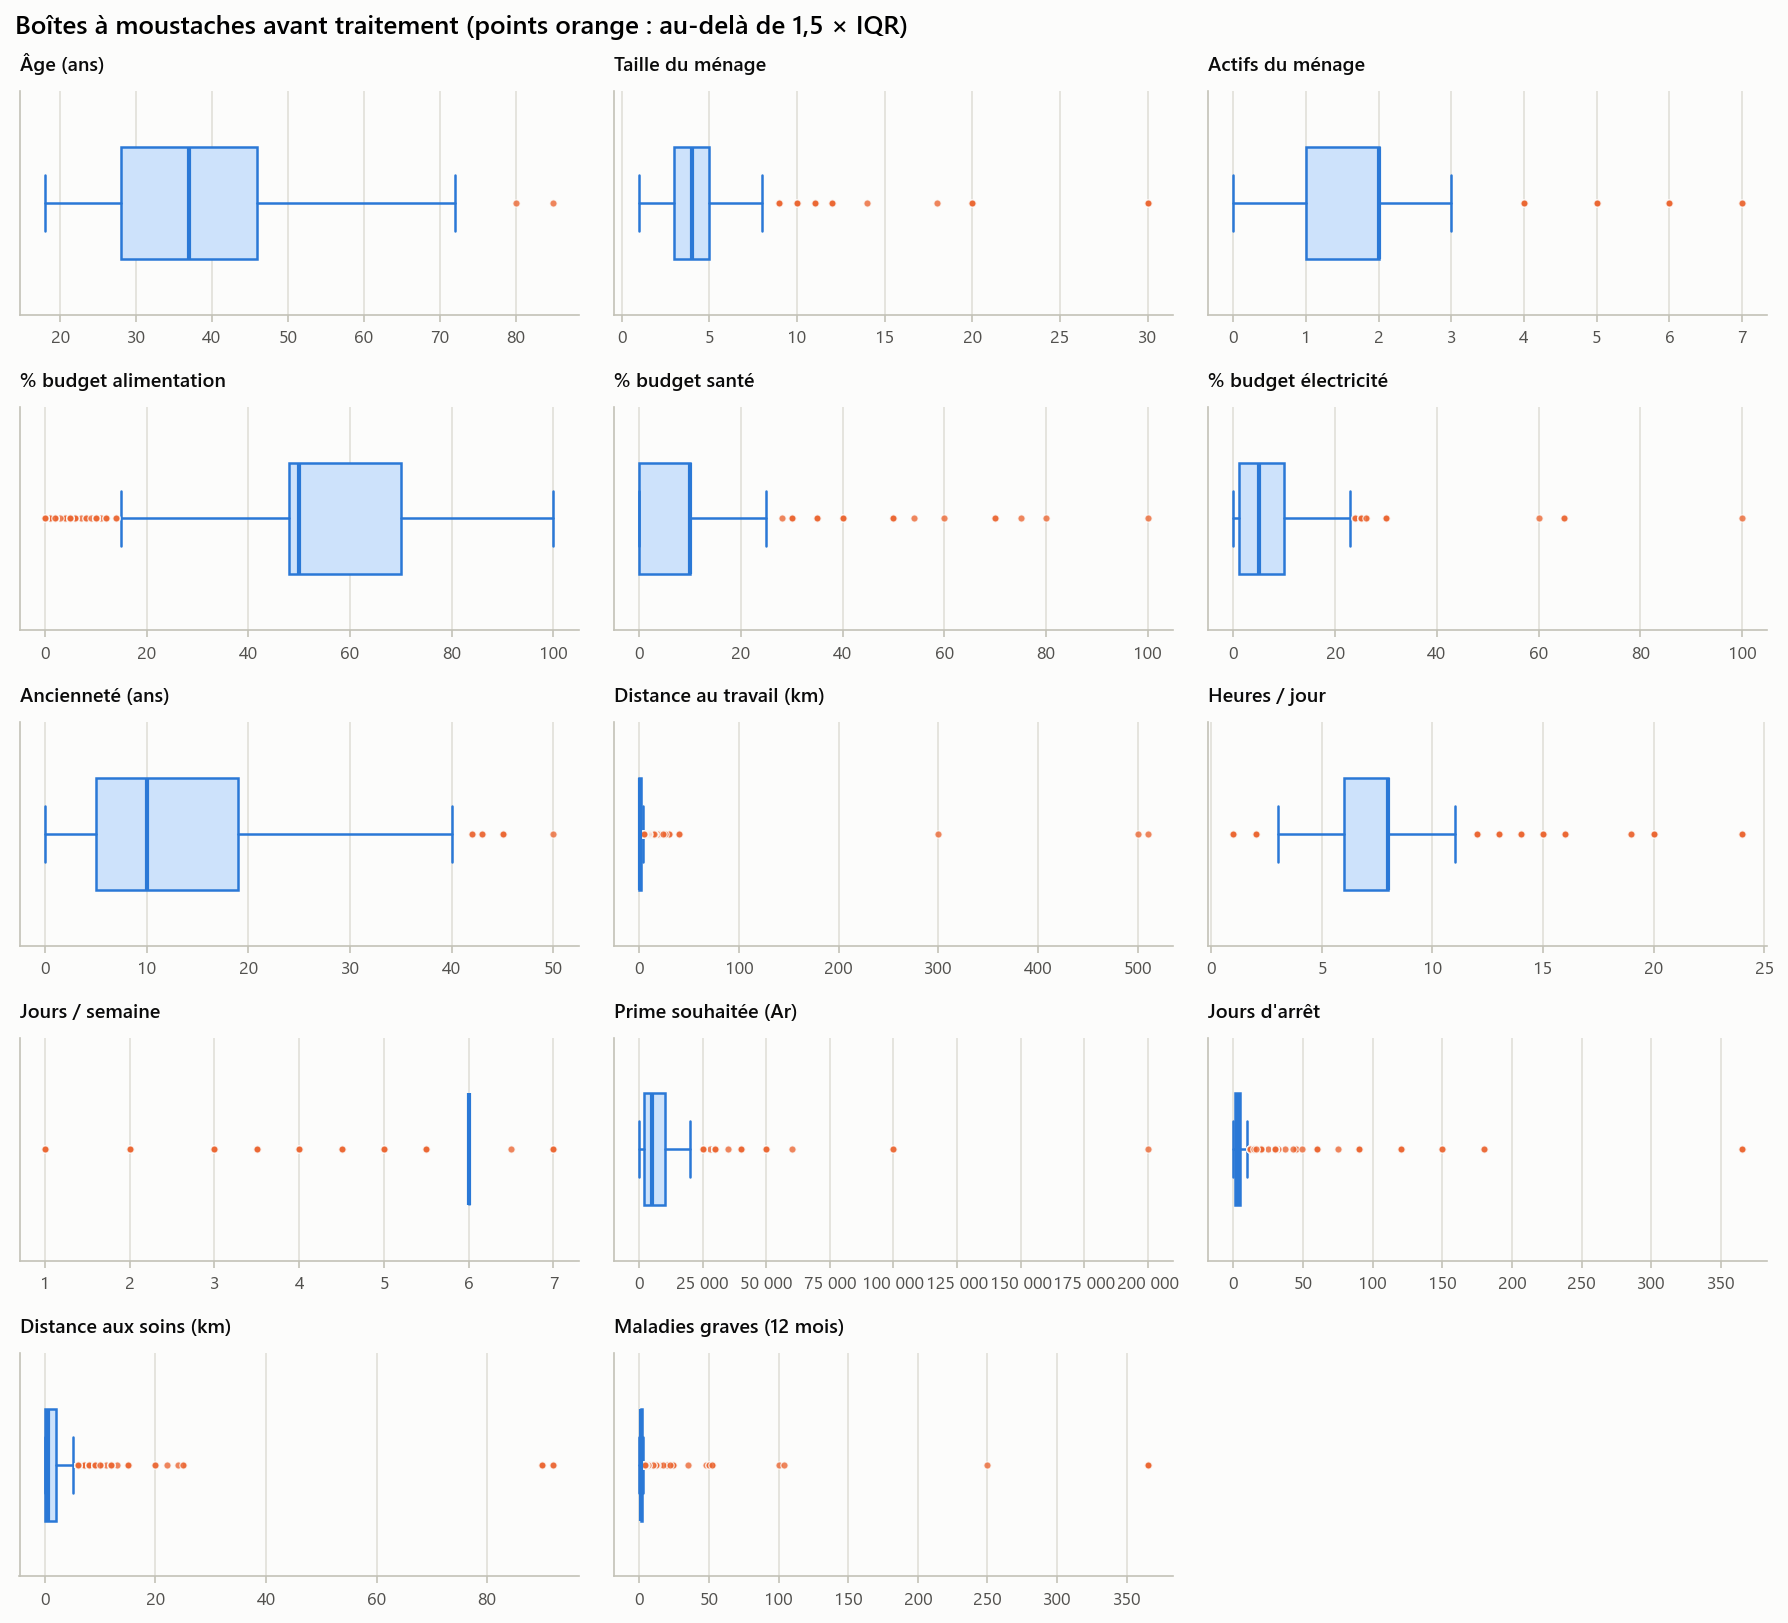

In [6]:
# Boîtes à moustaches avant traitement
liste = EXPLICATIVES + DESCRIPTIVES + ["nb_maladies_graves"]
fig, axes = plt.subplots(5, 3, figsize=(12, 11))
for ax, v in zip(axes.ravel(), liste + [None] * (15 - len(liste))):
    if v is None:
        ax.set_visible(False)
        continue
    boites(ax, df[v], LIBELLES[v])
fig.suptitle("Boîtes à moustaches avant traitement (points orange : au-delà de 1,5 × IQR)",
             x=0.01, ha="left")
fig.tight_layout()
o.sauver_figure(fig, RES, "boites_avant_traitement");

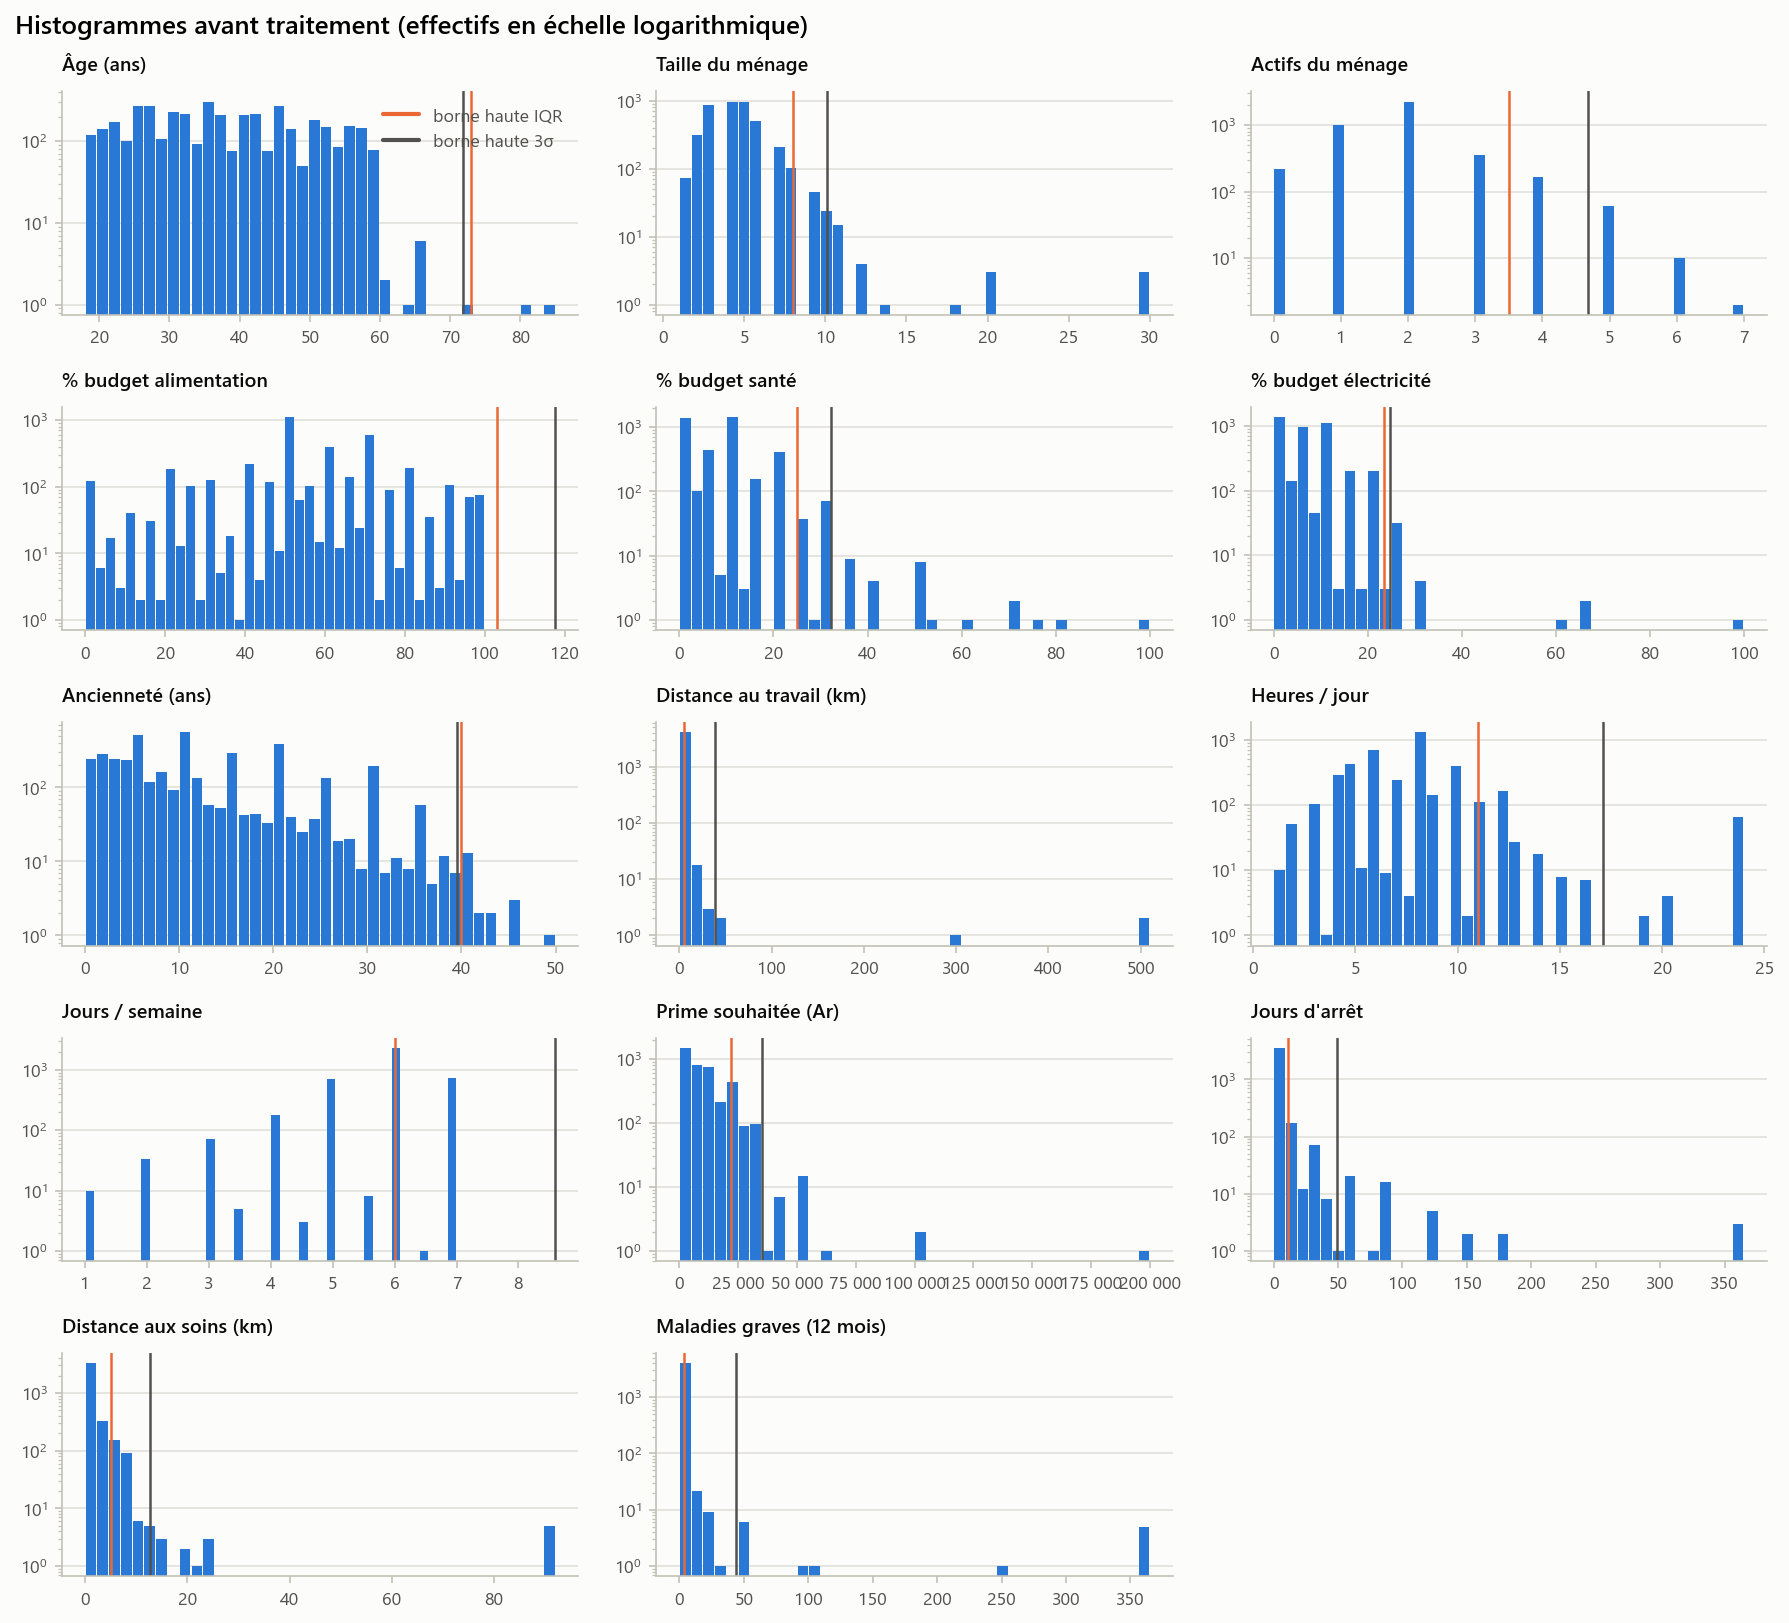

In [7]:
# Histogrammes avant traitement
fig, axes = plt.subplots(5, 3, figsize=(12, 11))
for ax, v in zip(axes.ravel(), liste + [None] * (15 - len(liste))):
    if v is None:
        ax.set_visible(False)
        continue
    s = df[v].dropna()
    ax.hist(s, bins=40, color=BLEU, rwidth=0.9)
    ax.axvline(det.loc[v, "borne_sup_iqr"], color=o.SERIES[1], lw=1.2)
    ax.axvline(det.loc[v, "borne_sup_3s"], color=C["encre2"], lw=1.2)
    ax.set_title(LIBELLES[v], fontsize=9.5)
    ax.set_yscale("log")
    ax.xaxis.set_major_formatter(o.format_milliers)
axes.ravel()[0].plot([], [], color=o.SERIES[1], label="borne haute IQR")
axes.ravel()[0].plot([], [], color=C["encre2"], label="borne haute 3σ")
axes.ravel()[0].legend(loc="upper right")
fig.suptitle("Histogrammes avant traitement (effectifs en échelle logarithmique)", x=0.01, ha="left")
fig.tight_layout()
o.sauver_figure(fig, RES, "histogrammes_avant_traitement");

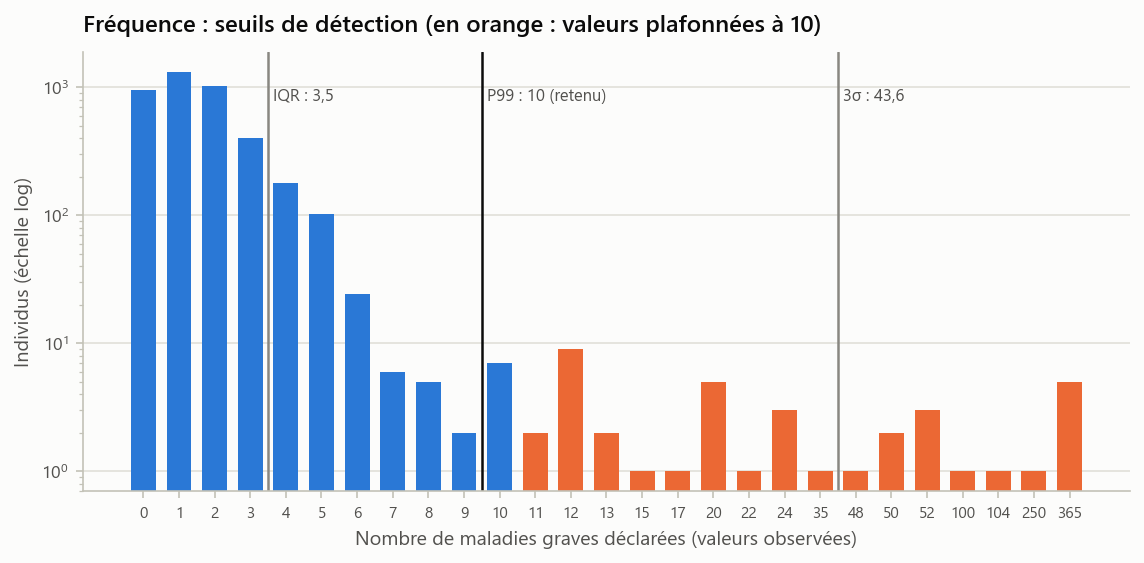

In [8]:
# Variable de fréquence : les trois seuils
fig, ax = plt.subplots(figsize=(9, 3.8))
s = df.nb_maladies_graves.dropna()
valeurs = np.sort(s.unique())
eff = s.value_counts().reindex(valeurs)
ax.bar(range(len(valeurs)), eff.values, color=[BLEU if v <= p99["nb_maladies_graves"] else o.SERIES[1]
                                               for v in valeurs], width=0.7)
ax.set_xticks(range(len(valeurs)), [f"{v:g}" for v in valeurs], fontsize=7.5)
ax.set_yscale("log")
ax.set_xlabel("Nombre de maladies graves déclarées (valeurs observées)")
ax.set_ylabel("Individus (échelle log)")
for seuil, nom, couleur in [(det.loc["nb_maladies_graves", "borne_sup_iqr"], "IQR : 3,5", C["attenue"]),
                            (p99["nb_maladies_graves"], "P99 : 10 (retenu)", C["encre"]),
                            (det.loc["nb_maladies_graves", "borne_sup_3s"], "3σ : 43,6", C["attenue"])]:
    x = np.searchsorted(valeurs, seuil) - 0.5
    ax.axvline(x, color=couleur, lw=1.2)
    ax.text(x + 0.15, eff.max() * 0.6, nom, fontsize=8, color=C["encre2"])
ax.set_title("Fréquence : seuils de détection (en orange : valeurs plafonnées à 10)")
o.sauver_figure(fig, RES, "seuils_frequence");

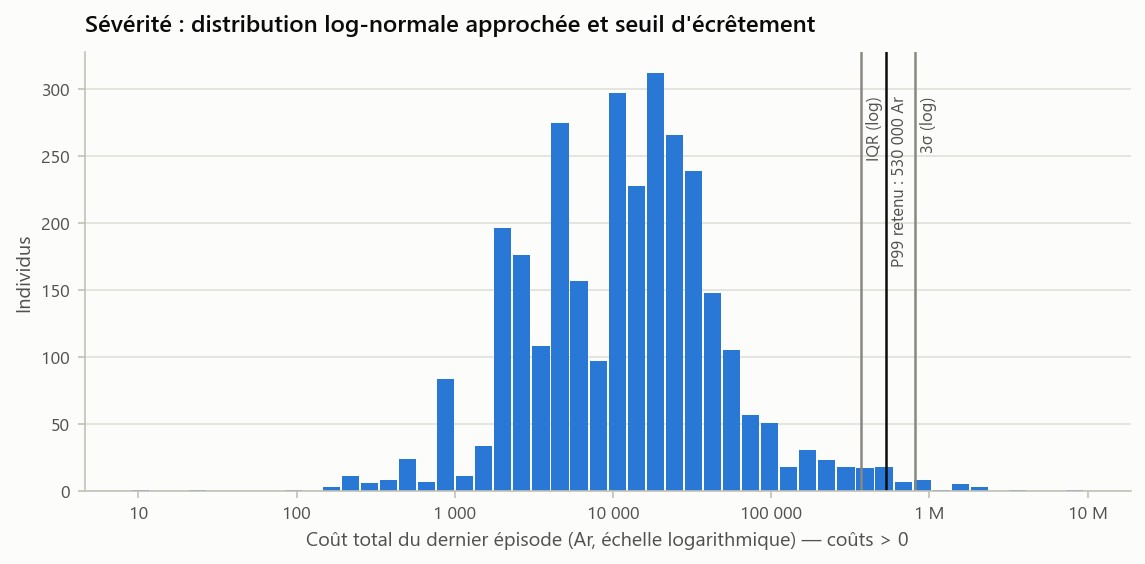

In [9]:
# Coût total : échelle logarithmique
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(log_cout, bins=50, color=BLEU, rwidth=0.9)
for x, nom, couleur in [(det_log["borne_sup_iqr"], "IQR (log)", C["attenue"]),
                        (det_log["borne_sup_3s"], "3σ (log)", C["attenue"]),
                        (np.log10(SEUIL_COUT), f"P99 retenu : {SEUIL_COUT:,.0f} Ar".replace(",", " "),
                         C["encre"])]:
    ax.axvline(x, color=couleur, lw=1.2)
    ax.text(x + 0.03, ax.get_ylim()[1] * 0.9, nom, fontsize=8, color=C["encre2"], va="top",
            rotation=90)
ticks = [1, 2, 3, 4, 5, 6, 7]
ax.set_xticks(ticks, ["10", "100", "1 000", "10 000", "100 000", "1 M", "10 M"])
ax.set_xlabel("Coût total du dernier épisode (Ar, échelle logarithmique) — coûts > 0")
ax.set_ylabel("Individus")
ax.set_title("Sévérité : distribution log-normale approchée et seuil d'écrêtement")
o.sauver_figure(fig, RES, "seuils_cout");

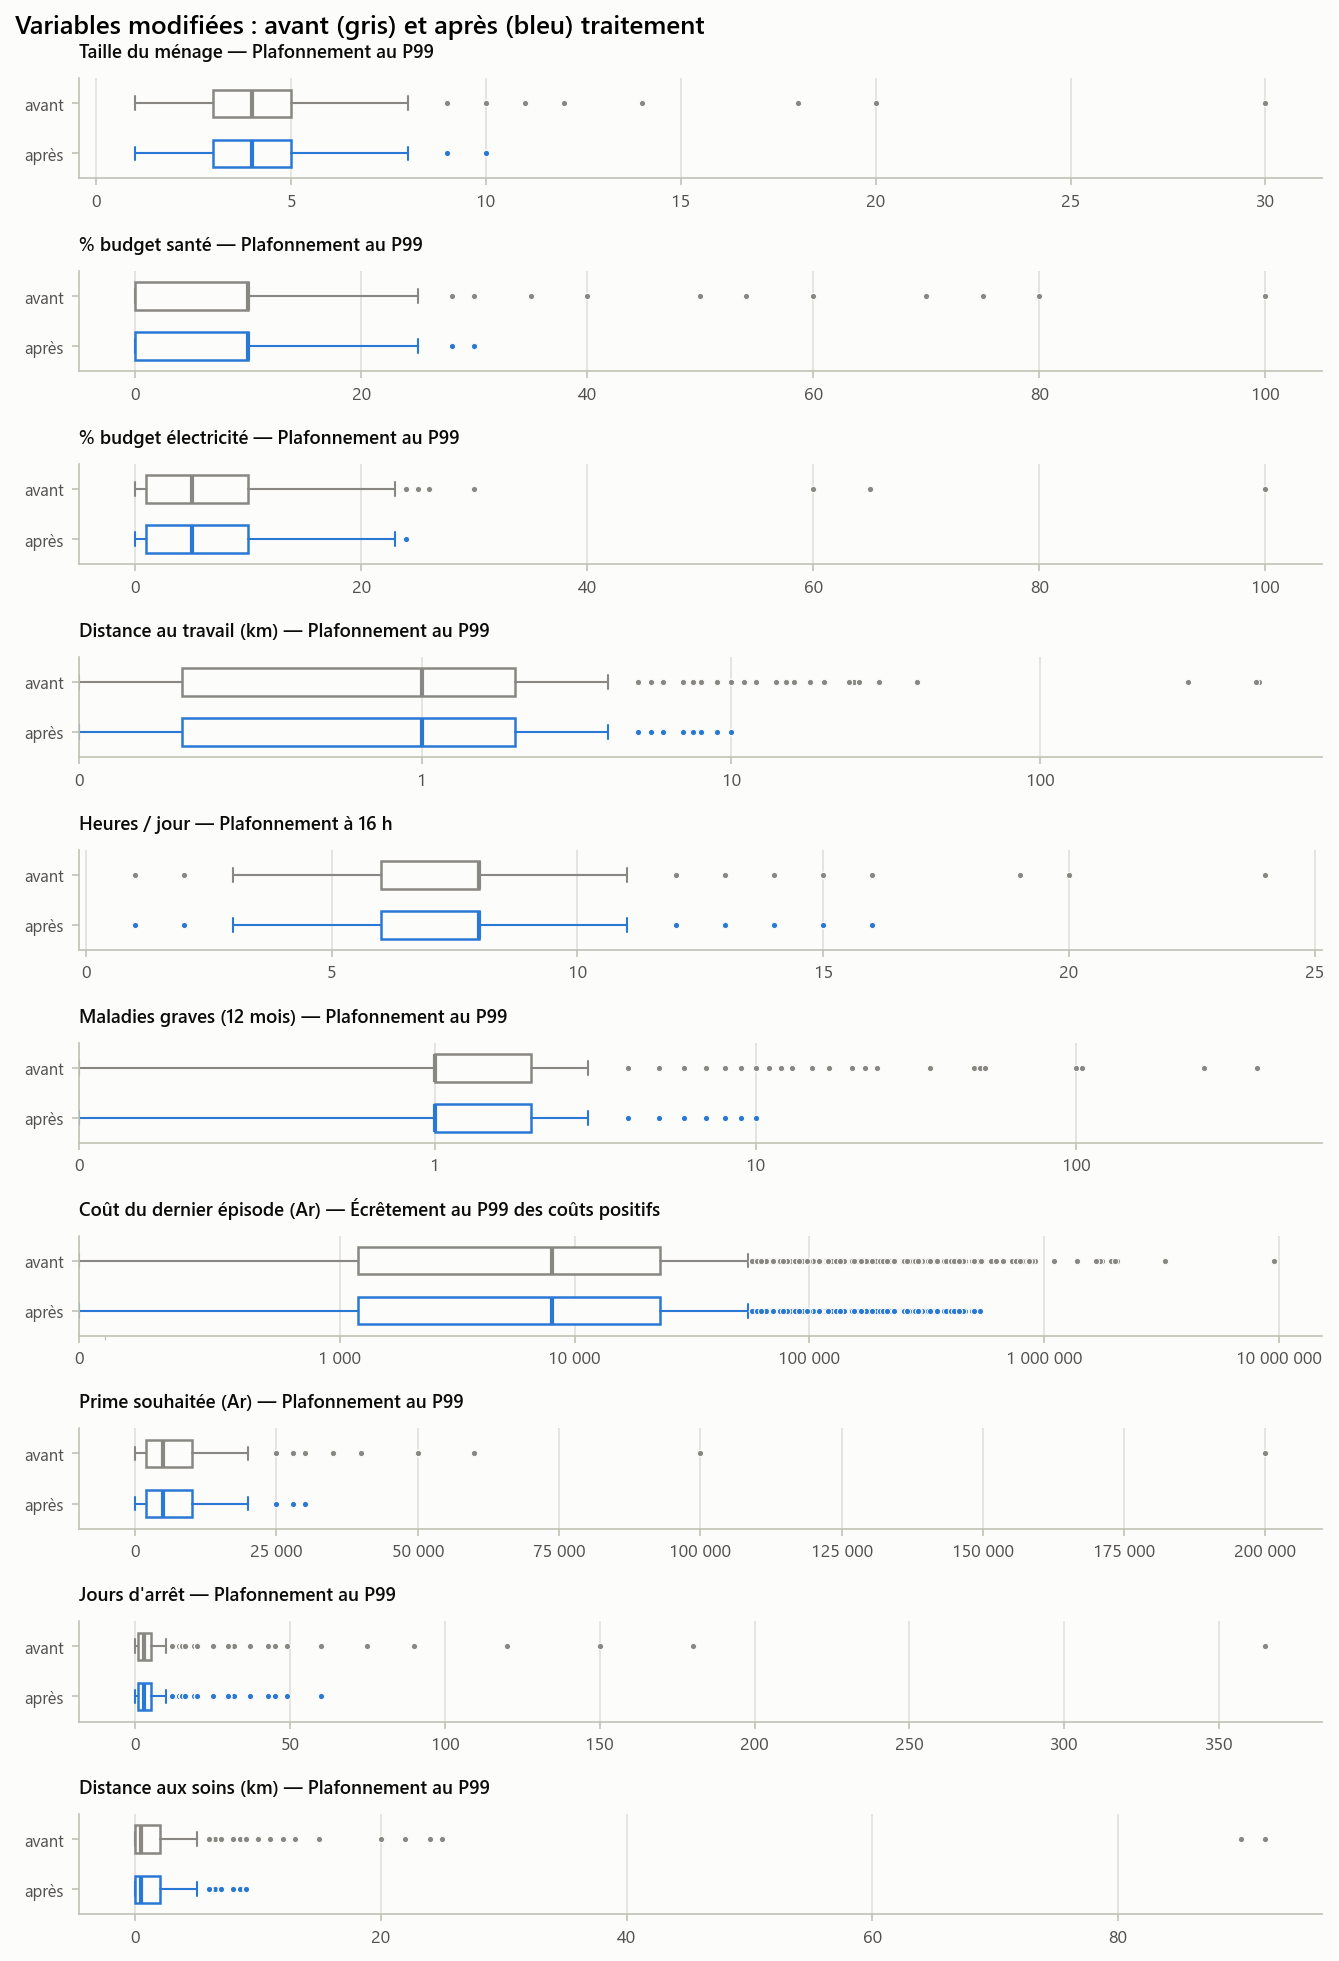


## Fichiers produits

- partie1_donnees\1.2_aberrantes\resultats\donnees_sans_aberrantes.csv
- partie1_donnees\1.2_aberrantes\resultats\donnees_sans_aberrantes.xlsx
- partie1_donnees\1.2_aberrantes\resultats\figures\avant_apres_traitement.png
- partie1_donnees\1.2_aberrantes\resultats\figures\boites_avant_traitement.png
- partie1_donnees\1.2_aberrantes\resultats\figures\histogrammes_avant_traitement.png
- partie1_donnees\1.2_aberrantes\resultats\figures\seuils_cout.png
- partie1_donnees\1.2_aberrantes\resultats\figures\seuils_frequence.png
- partie1_donnees\1.2_aberrantes\resultats\journal.txt
- partie1_donnees\1.2_aberrantes\resultats\tables\detection_aberrantes.csv
- partie1_donnees\1.2_aberrantes\resultats\tables\effet_cout.csv
- partie1_donnees\1.2_aberrantes\resultats\tables\effet_frequence.csv
- partie1_donnees\1.2_aberrantes\resultats\tables\traitement_aberrantes.csv


In [10]:
# Avant / après pour les variables modifiées
modifiees = strategie[strategie.valeurs_modifiees > 0].variable.tolist()
fig, axes = plt.subplots(len(modifiees), 1, figsize=(9, 1.25 * len(modifiees) + 0.8))
for ax, v in zip(axes, modifiees):
    for y, (serie, couleur) in enumerate([(traite[v], BLEU), (df[v], C["attenue"])]):
        s = serie.dropna()
        ax.boxplot(s, positions=[y], vert=False, widths=0.55, patch_artist=True,
                   boxprops=dict(facecolor=C["surface"], edgecolor=couleur, lw=1.2),
                   medianprops=dict(color=couleur, lw=2), whiskerprops=dict(color=couleur),
                   capprops=dict(color=couleur),
                   flierprops=dict(marker="o", markersize=3, markerfacecolor=couleur,
                                   markeredgecolor=C["surface"], markeredgewidth=0.5))
    ax.set_yticks([0, 1], ["après", "avant"], fontsize=8)
    if v in ("cout_total", "distance_travail", "nb_maladies_graves"):
        ax.set_xscale("symlog", linthresh={"cout_total": 1000}.get(v, 1))
        ax.set_xlim(left=0, right=df[v].max() * 1.6)
        if v == "cout_total":
            ax.set_xticks([0, 1e3, 1e4, 1e5, 1e6, 1e7])
    ax.set_title(f"{LIBELLES[v]} — {strategie.set_index('variable').loc[v, 'traitement']}", fontsize=9)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x")
    ax.xaxis.set_major_formatter(o.format_milliers)
fig.suptitle("Variables modifiées : avant (gris) et après (bleu) traitement", x=0.01, ha="left")
fig.tight_layout()
o.sauver_figure(fig, RES, "avant_apres_traitement")

log.section("Fichiers produits")
for f in sorted(RES.rglob("*.*")):
    log("-", f.relative_to(o.RACINE))
log.fermer();

---

Les tableaux complets sont dans `resultats/tables/`, les figures dans `resultats/figures/` et la sortie intégrale dans `resultats/journal.txt`. Commentaires et décisions : [README.md](README.md).